In [83]:
import numpy as np
import pandas as pd
import anndata as ad
%matplotlib inline
import matplotlib.pyplot as plt

import os
import gzip
import shutil
import pickle
import re
import json
import requests
import time
import warnings
import sys
from pathlib import Path

import scanpy as sc
import igraph
import gseapy

import scipy.spatial.distance as dist

from scipy import stats
from scipy.stats import spearmanr
from scipy.spatial import cKDTree
from scipy.stats import fisher_exact

import networkx as nx
from nodevectors import Node2Vec

from sklearn import linear_model
from sklearn.linear_model import LassoLarsCV
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn import svm
from sklearn.utils import resample
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn import metrics


import warnings
from sklearn.utils._testing import ignore_warnings
from sklearn.exceptions import ConvergenceWarning


import seaborn as sns
def flatten(xss):
    return [x for xs in xss for x in xs]

This is meant to contain code for key methods throughout the manuscript. We do NOT intend it to be a 1-to-1 reprisal of every single method which is employed in the manuscript -- rather, it is capturing methods that are either i) novel or ii) not easily found in the standard literature, grad school curricula, etc. 

Here is a list of topics that are NOT covered, attempting to follow the order of the Methods:

- Converting between raw counts, CPM, TPM, FPKM, zFPKM. We use GRcH38 throughout this work, and so our length of exons/transcripts is derived from this. 

- Constructing a quasi- time series by conjoining adjacent age buckets, averaging expression when multiple donors exist per year-of-age and interpolating when donors are absent. 

- Certain scalings of certain code elements. For instance, we hopefully document quite thoroughly how to compute CCM between two gene quasi- time series as a function of embedding dimension E, how to analyze it, but we don't explicitly put in a Jupyter notebook how to run it on all genes and obtain a network; this was done in Snakemake (or any other pipeline system) and requires time and memory which we find incompatible with a healthy documentary codebase. Likewise for scaling up queries to BioGRiD and training AdaBoost models to the same depth and number-of-models that are employed in the paper. 

- Repeating methods. For instance, we use our AdaBoost with abstention on both the scRNA and CellPaint data. Rather than bog down the documentation, we decided to walk through this in detail in one case only (CellPaint, which is the stronger result in the manuscript and therefore the claim that likely invites more active vetting).

- Employing certain packages that we use straight out-of-the-box; here we would just be giving an inferior documentation compared to what can be found at the package source. This pertains chiefly to tsfresh, but also likely extends to really basic applications of networkx and scanpy which are not covered in the relevant sections.

- Certain methods which we not performed by us, but rather by a CRO handling the data. For instance, the raw CellPaint data was extracted by the Broad Institute for us (they also performed the imaging, staining, and so forth). In an ideal world the intermediary steps in CellProfiler would be documented. However, the Broad largely has its own packages for CellProfiler, which in some cases may be proprietary, and in any case were not implemented by us. We do our best to document most of the step in the Methods.

- The graph convolutional neural network -- this would require heavy machinery (PyTorch) that would significantly densify this code release, all to show what is a negative result in the manuscript (that is to say, the GCN never converges to a stable, predictive model)



Start-up: this data is extremely large (it comprises most of the raw data pertaining to the manuscript), and takes XXX minutes to load in given the machine specs in the README

In [3]:
%%time
with open('MethodsDataDict.pkl','rb') as data_file:
    MethodsDict=pickle.load(data_file)

CPU times: user 48.5 s, sys: 34.3 s, total: 1min 22s
Wall time: 1min 22s


In [4]:
MethodsDict.keys()

dict_keys(['CCM', 'scRNA', 'CCMStatistics', 'CellPaint', 'Node2Vec'])

In [5]:
for key in MethodsDict.keys():
    print(MethodsDict[key].keys())

dict_keys(['GTExData_processed', 'Edgelist'])
dict_keys(['Raw_scRNA_Data', 'ScalePlexDemultiplexing', 'Gencode', 'Plasmid_Corrupted_Control_Cells', 'CellCycleGenes'])
dict_keys(['SpearmanPassingDict', 'DEdict', 'GFP_degs', 'DeepSemNetwork', 'PCorrNetwork'])
dict_keys(['RawData', 'PlateMap'])
dict_keys(['NetworkA', 'NetworkB', 'NetworkE', 'NetworkF', 'ExtraFeatures'])


In [10]:
1

1

# CCM and related methods

CCM can be cooked down to a handful of lines, as well as accelerated, by implementing some structures that replace memory cost with storage cost. In particular, rather than calculating nearest neighbors iteratively at every library length L and embedding dimension E, the largest nearest neighbor tree per value of E (that is, the KD tree at max L) can be generated only once and masked for all L<L_max. 

These first two commands are simple. shadowManifold creates a delay embedding (sometimes called 'shadow manifold' due to the univariate nature and the fact that, via Takens' theorem, it is a diffeomorphism of the global manifold). makeKDtree builds on this to create the max-L KD tree for every quasi- time series in 'genelist'


In [9]:
def shadowManifold(X, E, tau=1):
    # This makes a "shadow manifold", an E-dimensional delay-embedding of X:
    
    return [X[np.arange(i, i - (E - 1) * tau - 1, -tau)] for i in np.arange(0 + (E - 1) * tau, len(X))]

def makeKDtree(data_df,genelist):
    # CCM can be significantly accelerated by building trees ahead of time and holding them in storage rather than memory
    BigDict={}
    for gene in genelist:
        BigDict[gene]={}
        for EE in [3,4,5,6,7,8,9,10]:
            x_data=np.array(data_df[gene].values)
            x_data+=np.random.rand(len(x_data))*0.001*np.abs(np.min(x_data))
            shadow_M_X = shadowManifold(x_data, int(EE), 1)
            shadow_kdtree = cKDTree(shadow_M_X, leafsize=10)
            dist, ind = shadow_kdtree.query(shadow_M_X, k=int(len(shadow_M_X)))
            BigDict[gene][EE]=[dist,ind,shadow_kdtree]
    return BigDict
    

The next code is the main 'guts' of CCM, using the nearest-neighbor structure (in delay embedding / 'shadow manifold') of variable X to predict the value of variable Y:

In [10]:
def generateYApprox(KDtreeDict, Xname, Ydata, E):
   
    dists=KDtreeDict[Xname][E][0] # Pull the NN distances from the tree
    inds=KDtreeDict[Xname][E][1] # Pull the neighbor indices from the tree

    dist_neigh, Y_neigh = [], []
    mask_ceiling=len(Ydata) # Getting L, the current library length
    
    # This next loop is just applying the mask
    for zz in range(mask_ceiling-E+1):

        dist_neigh.append(list(dists[zz,:][np.where(inds[zz,:]<mask_ceiling)][1:E+1]))
        Y_neigh.append(list(Ydata[inds[zz,:][np.where(inds[zz,:]<mask_ceiling)][1:E+1]]))
       
    #Convert list to array
    Y_neigh=np.array(Y_neigh)
    dist_neigh=np.array(dist_neigh)

    # weights
    u = np.exp(-dist_neigh / dist_neigh[:, 0][:, None])
    u /= u.sum(axis=1)[:, None]

    Y_tilde = np.sum(u*Y_neigh, axis=1)
    return Y_tilde

We can use this to run some basic tests, and show how we scale up to building the full network:

In [11]:
MethodsDict['CCM'].keys()

dict_keys(['GTExData_processed', 'Edgelist'])

In [12]:
quasits=MethodsDict['CCM']['GTExData_processed']
quasits.head()

,age,MTND2P28,MTCO1P12,MTATP6P1,NOC2L,ISG15,AGRN,SDF4,B3GALT6,UBE2J2,...,MT-ND4L,MT-ND4,MT-ND5,MT-ND6,MT-CYB,LAMB3,MATR3,ATG5,SIRT1,id
0,20,1180.000000,20.960000,2911.0000,133.100000,79.840000,27.000000,350.1000,45.870000,66.2900,...,13230.000000,26660.000000,4458.000000,3569.00,12700.000000,10.990000,6.951000,24.850000,22.930000,1
1,21,467.877778,52.763333,1548.5000,98.576667,53.655556,32.885556,274.2000,33.184444,43.3300,...,7777.666667,15924.444444,4208.333333,4763.00,9392.444444,8.104889,6.044111,19.973333,17.934444,1
2,22,517.250000,33.343750,1719.7125,97.333750,74.693750,32.478750,308.5125,32.396250,46.1875,...,8081.125000,16877.500000,4482.375000,5022.25,10618.125000,8.117000,6.464250,20.181250,19.343750,1
3,23,474.800000,52.364000,1976.8000,132.624000,54.084000,29.820000,272.5200,37.564000,42.7080,...,9200.200000,18930.000000,4375.400000,5115.40,9509.200000,13.307400,6.791600,21.370000,17.768000,1
4,24,255.950000,45.040000,1390.0000,94.337500,38.240000,52.560000,285.5500,32.700000,32.2975,...,7156.000000,15320.000000,5379.500000,6398.50,8550.500000,6.896250,4.565000,16.952500,15.880000,1


Let's expand on the fibronectin - collagen relationship that was used as an example in Figure 1D, to lay out the steps to process the "full" network. In ReplicateFigures.ipynb, we simply fix E=3 as the embedding dimension. In normal practice, we sweep from E=3 to E=10. We start by making the NN trees for the focal genes (to scale, include every gene):

In [ ]:
'ANXA2', 'ITGA10'

In [13]:
outtree=makeKDtree(quasits,['COL1A2','FN1'])

Now we deviate from the figure-making notebook in two ways -- by expanding the range of E, and by recording both the Pearson correlation between the approximant and the true data (which we shorthand as the 'CCM strength', and record at full library length) as well as the Spearman correlation between the CCM strength as a function of library length and the library length (looking for monotonicity).

In [14]:
%%time
ApproximantDict={}
EndLibraryCCMStrength=[]
SpearmanPval=[]
for EE in [3,4,5,6,7,8,9,10]:
    Y_tilde=generateYApprox(outtree,'COL1A2',quasits['FN1'],EE)
    ApproximantDict[EE]=Y_tilde
    PearsonBox=[]
    for liblen in range(EE+1,len(Y_tilde)):
        [r,p]=stats.pearsonr(Y_tilde[:liblen],quasits['FN1'][:liblen])
        PearsonBox.append(r)
    EndLibraryCCMStrength.append(PearsonBox[-1])
    [rS,pS]=stats.spearmanr(PearsonBox,range(len(PearsonBox)))
    SpearmanPval.append(pS)

CPU times: user 296 ms, sys: 18.3 ms, total: 314 ms
Wall time: 306 ms


In [16]:
for EE in [3,4,5,6,7,8,9,10]:
    print('Embedding dimension '+str(EE)+': End-library CCM strength '+str(EndLibraryCCMStrength[EE-3])+', Spearman p-value '+str(SpearmanPval[EE-3]) )
          

Embedding dimension 3: End-library CCM strength 0.6321775262019342, Spearman p-value 2.5460294997048016e-17
Embedding dimension 4: End-library CCM strength 0.6303333405042956, Spearman p-value 1.0833260545810864e-16
Embedding dimension 5: End-library CCM strength 0.786109898915639, Spearman p-value 1.1336009580044544e-15
Embedding dimension 6: End-library CCM strength 0.7115094733343923, Spearman p-value 9.651853197358322e-07
Embedding dimension 7: End-library CCM strength 0.6946561971196712, Spearman p-value 0.13657836210963875
Embedding dimension 8: End-library CCM strength 0.6769711885012353, Spearman p-value 0.2582517553746171
Embedding dimension 9: End-library CCM strength 0.6782189651525591, Spearman p-value 0.00924959111493032
Embedding dimension 10: End-library CCM strength 0.6382088424329193, Spearman p-value 0.09774235531418328


In this particular instance, all embedding dimensions except E=7 and E=8 would be considered valid candidates for the "best" embedding for this gene-gene pair. Of these, E=5 has the supremum end-library CCM strength, so that would be the "best" embedding chosen and the value of the end-library CCM strength that would be used for relevant analysis portions of the manuscript.

# BioGRiD API call

NOTE that this will not work on its own -- you need your own API credentials (the parameter "accesskey" below). It is just documented for openness.

In [35]:
MethodsDict['CCM'].keys()

dict_keys(['GTExData_processed', 'Edgelist'])

In [37]:
CCM_Edgelist=MethodsDict['CCM']['Edgelist']
CCM_Edgelist[0:10]

[('ANXA2', 'ITGA10'),
 ('ANXA2', 'IFT52'),
 ('ANXA2', 'SF3B6'),
 ('ANXA2', 'CHD1L'),
 ('ANXA2', 'OTUD5'),
 ('ANXA2', 'SNRPA'),
 ('ANXA2', 'MGAT1'),
 ('ANXA2', 'TOPBP1'),
 ('ANXA2', 'DCTN3'),
 ('ANXA2', 'MT-ND2')]

In [ ]:
request_url='https://webservice.thebiogrid.org/interactions'

In [ ]:
%%time
annot=[] #this will store how many citations are indexed for each pair
testsize=10 #Check the first TESTSIZE pairs
for pair in CCM_EdgeList[:testsize]:
    params = {
    "accesskey": YOUR_ACCESS_KEY,
    "format": "json",  # Return results in TAB2 format
    "geneList": "|".join(pair),  # Must be | separated
    "searchNames": "true",  # Search against official names
    "includeInteractors": "false",  # Set to true to get any interaction involving EITHER gene, set to false to get interactions between genes
    "includeInteractorInteractions": "false",  # Set to true to get interactions between the geneList’s first order interactors
    "taxId": 9606,  # The taxId for homo sapiens
    "includeEvidence": "false",  # If false "evidenceList" is evidence to exclude, if true "evidenceList" is evidence to show
}
    try:
        r = requests.get(request_url, params=params)
        interactions = r.json()
        annot.append(len(interactions))
    except:
        no_result=1
        annot.append('NULL')

In [ ]:
plt.hist(annot)

# scRNA data processing

Load in the raw data. This is equivalent to the [processed] GEO files, stacked into a dictionary format:

In [7]:
datadict=MethodsDict['scRNA']['Raw_scRNA_Data']
print(datadict.keys())

dict_keys(['Ctrl.merged.filtered.matrix', 'Sample1.merged.filtered.matrix', 'Sample2.merged.filtered.matrix', 'Sample3.merged.filtered.matrix'])


At this juncture, the cells have not been fully demultiplexed:

In [28]:
datadict['Sample1.merged.filtered.matrix'].obs

""
AAACCATAGAGAGAAGGTTTAGAGGCGTT_Sample1.RNA-A-AP4
AAACCATAGAGAGAAGGTTTTGCGAGCAT_Sample1.RNA-A-AP4
AAACCATAGAGAGCCAAGGAAGTAGCTCA_Sample1.RNA-A-AP4
AAACCATAGAGAGCCAAGGAATACGATAA_Sample1.RNA-A-AP4
AAACCATAGAGAGCCAAGGAGCCGTAGTT_Sample1.RNA-A-AP4
...
TTTGCTTAGTTCGCCTCCACGAATGGAGC_Sample1.RNA-A-AP2
TTTGCTTAGTTCGCCTCCACGCGGCCATA_Sample1.RNA-A-AP2
TTTGCTTAGTTCGCCTCCAGACTGGACCA_Sample1.RNA-A-AP2
TTTGCTTAGTTCGCCTCCAGCTAACGGAT_Sample1.RNA-A-AP2


Retrieve the demultiplexing information:

In [17]:
ScalePlexDict=MethodsDict['scRNA']['ScalePlexDemultiplexing']
ControlPlex=ScalePlexDict['Control']
Sample1Plex=ScalePlexDict['Sample1']
Sample2Plex=ScalePlexDict['Sample2']
Sample3Plex=ScalePlexDict['Sample3']

Process the samples:

In [9]:
%%time
ddict={}

# Keep cells passing internal ScalePlex QC
ddict['ctrl']=datadict['Ctrl.merged.filtered.matrix'][ControlPlex.index,:]
ddict['s1']=datadict['Sample1.merged.filtered.matrix'][Sample1Plex.index,:]
ddict['s2']=datadict['Sample2.merged.filtered.matrix'][Sample2Plex.index,:]
ddict['s3']=datadict['Sample3.merged.filtered.matrix'][Sample3Plex.index,:]

# Mark a cell's received transgene in the .obs
ddict['ctrl'].obs['Gene']=ControlPlex.Gene.values
ddict['s1'].obs['Gene']=Sample1Plex.Gene.values
ddict['s2'].obs['Gene']=Sample2Plex.Gene.values
ddict['s3'].obs['Gene']=Sample3Plex.Gene.values

# Concat the four split plates into one anndata
masterad=ddict['ctrl']
masterad=masterad.concatenate([ddict['s1'],ddict['s2'],ddict['s3']])

<timed exec>:10: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
<timed exec>:11: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
<timed exec>:12: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
<timed exec>:13: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/opt/conda/lib/python3.9/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],
/opt/conda/lib/python3.9/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. 

CPU times: user 4.43 s, sys: 4.18 s, total: 8.61 s
Wall time: 8.6 s


Most of what follows is pretty standard ScanPy / other scRNA normalizations and QC. And most of it is somewhat interchangeable as far as order of operations. However, one subtlety is that the percentage of counts dedicated to mitochondrial, ribosomal, and MALAT1 RNA will vary slightly depending on if this is calculated BEFORE or AFTER various trimmings of the gene set involved in the .var -- I like to perform this first, it feels more "honest", as it will be an immutable quantity; otherwise, it will vary according to each person's approach to normalization.

In [12]:
%%time
masterad.var["mito"] = masterad.var_names.str.startswith("MT-")
masterad.var["ribo"] = masterad.var_names.str.startswith("RPL")+masterad.var_names.str.startswith("RPS")
masterad.var["malat"] = masterad.var_names.str.startswith("MALAT")

sc.pp.calculate_qc_metrics(masterad, qc_vars=["mito","ribo","malat"], inplace=True,log1p=False)

CPU times: user 1min 3s, sys: 2.07 s, total: 1min 5s
Wall time: 38.9 s


Next -- to make the scRNA data more "apples-to-apples" with the CCM analysis, we will restrict our universe of genes (the .var) to protein coding genes -- this jives better with GTEx data:

In [79]:
Gencode=MethodsDict['scRNA']['Gencode']
Gencode.head()
# This is Gencode V28, which has the annotations we are after

,Geneid,GeneSymbol,Chromosome,Start,End,Class,Strand,Length
0,ENSG00000223972.5,DDX11L1,chr1,11869,14409,transcribed_unprocessed_pseudogene,+,2540
1,ENSG00000227232.5,WASH7P,chr1,14404,29570,unprocessed_pseudogene,-,15166
2,ENSG00000278267.1,MIR6859-1,chr1,17369,17436,miRNA,-,67
3,ENSG00000243485.5,MIR1302-2HG,chr1,29554,31109,lincRNA,+,1555
4,ENSG00000284332.1,MIR1302-2,chr1,30366,30503,miRNA,+,137


In [80]:
Gencode_Restricted=Gencode[Gencode.Class.isin([' protein_coding', ' processed_pseudogene'])]
CodingGenes=[i[1:] for i in Gencode_Restricted.GeneSymbol.values] # the [1:] is required because this entire spreadsheet has whitespace in front of every entry

In [82]:
print(len(CodingGenes))
CodingGenes[0:5]

30096


['OR4F5', 'CICP27', 'RP11-34P13.15', 'RP11-34P13.16', 'RPL23AP21']

In [111]:
masterad=masterad[:,masterad.var.index.isin(CodingGenes)]
sc.pp.normalize_total(masterad, target_sum=1e6)

/opt/conda/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:169: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Next, we remove the fistful of cells which were meant to be control cells, yet which we found expressing our plasmid backbone

In [125]:
Plasmid_Corrupted=MethodsDict['scRNA']['Plasmid_Corrupted_Control_Cells']
Plasmid_Corrupted.head()

,0
0,AACCTCATTACTATGCAATAAGTAGCTCA_Ctrl.RNA-A-AP2
1,TTTGCTACTTCTGATACCACCGTATGATT_Ctrl.RNA-A-AP3
2,ACTTGATTGCGACGCGACTAGAGGAGAAT_Ctrl.RNA-A-AP3
3,AACGTAATCAAGACCGTTGCCAGATACGG_Ctrl.RNA-A-AP4
4,TGTTAAGACAACCTGCGTAGCATATGAGC_Ctrl.RNA-A-AP2


In [126]:
OffenderList=[i+'-0' for i in Plasmid_Corrupted['0'].values]

masterad=masterad[~masterad.obs.index.isin(OffenderList),:]

At this point we can take a brief detour to calculate the imputed cell cycle for each cell. We do not use this very extensively in the analysis, but I mention it in passing, so it is worth doing for some kind of 'completeness'.

I do this as a copy of the current dataframe, as it log1p's and Z-score's the data, which is not something I want in there permanently:

In [151]:
%%time
cellcycle=masterad.copy()
sc.pp.log1p(cellcycle)
sc.pp.scale(cellcycle)
cell_cycle_genes = MethodsDict['scRNA']['CellCycleGenes']
s_genes = cell_cycle_genes[:42]
g2m_genes = cell_cycle_genes[42:]

s_genes = [x for x in s_genes if x in cellcycle.var_names]
g2m_genes =[x for x in g2m_genes if x in cellcycle.var_names]

sc.tl.score_genes_cell_cycle(cellcycle, s_genes=s_genes, g2m_genes=g2m_genes)


CPU times: user 2min 10s, sys: 38.5 s, total: 2min 48s
Wall time: 2min 48s


I will, however, take the imputed scores and stick them back in the "real" AnnData:

In [196]:
masterad.obs['S_score']=cellcycle.obs['S_score']
masterad.obs['G2M_score']=cellcycle.obs['G2M_score']
masterad.obs['phase']=cellcycle.obs['phase']
masterad.obs.head()

,Gene,batch,n_genes_by_counts,total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mito,pct_counts_mito,total_counts_ribo,pct_counts_ribo,total_counts_malat,pct_counts_malat,S_score,G2M_score,phase
AAACCATAGAACCTGCGTAAGATTACGTT_Ctrl.RNA-A-AP3-0,ANXA2,0,2654,4731.0,22.505157,28.402431,36.101060,50.764458,66.0,1.395054,30.500000,0.644684,84.0,1.775523,0.042329,-0.027121,S
AAACCATAGAACCTGCGTATGATTAGGTA_Ctrl.RNA-A-AP3-0,OLD,0,2424,4202.0,20.645333,27.166040,36.284321,52.982723,35.0,0.832937,39.000000,0.928129,89.0,2.118039,-0.116224,-0.122896,G1
AAACCATAGAAGAAGCTAGACGGCGTTAA_Ctrl.RNA-A-AP3-0,YOUNG,0,1820,2639.0,19.107163,25.716808,34.962733,53.542999,22.0,0.833649,17.500000,0.663130,86.0,3.258810,-0.222663,-0.158222,G1
AAACCATAGAAGAAGCTAGAGATTACGTT_Ctrl.RNA-A-AP3-0,TP53,0,3109,4446.0,8.299595,12.973459,20.343380,35.787973,20.0,0.449843,26.500000,0.596041,27.0,0.607287,0.115465,0.042888,S
AAACCATAGAAGAAGCTAGCATTATTATT_Ctrl.RNA-A-AP3-0,OLD,0,4433,11432.0,19.889942,26.413359,34.777974,49.268735,149.0,1.303359,98.833344,0.864532,168.0,1.469559,-0.284687,0.000531,G2M


We now move on to differential expression. In the interest of time (running for all genes can take quite a bit of this, let's do a mini-example on GFP:

In [184]:
%%time
deg_ad=ad.concat([masterad[masterad.obs[masterad.obs.Gene=='OLD'].index,:],masterad[masterad.obs[masterad.obs.Gene=='GFP'].index,:]])
sc.tl.rank_genes_groups(deg_ad,'Gene',verbose=False);

deg_pvals=pd.DataFrame(deg_ad.uns['rank_genes_groups']['pvals_adj'])
deg_names=pd.DataFrame(deg_ad.uns['rank_genes_groups']['names'])

GFP_deg_results=list(set(flatten(list(deg_names.loc[deg_pvals[deg_pvals['OLD']<0.05].index,['OLD']].values))+flatten(list(deg_names.loc[deg_pvals[deg_pvals['GFP']<0.05].index,'GFP'].values))))


CPU times: user 5.07 s, sys: 433 ms, total: 5.5 s
Wall time: 5.5 s


/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:422: RuntimeWarning: divide by zero encountered in log2
  self.stats[group_name, 'logfoldchanges'] = np.log2(
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow

We can compare this to two other versions of the GFP-induced DEGs, which should completely agree -- one stored in our dictionary of differential expression results, and one stored separately for analyses where GFP DEGs are removed from consideration:

In [186]:
dedict=MethodsDict['CCMStatistics']['DEdict']
GFPdegs=MethodsDict['CCMStatistics']['GFP_degs']

In [ ]:
print(len(list(set(dedict['GFP'])-set(GFPdegs))))
print(len(list(set(GFP_deg_results)-set(GFPdegs))))

0
11


Good. Scaling up should look something like the following. The list "badgenes" contains the control samples ('OLD' and 'YOUNG') as well as the 14 genes that had fewer than 100-cell coverage. This shouldn't take hours -- something like 30 minutes on the specs given in the README seems to be about right:

In [206]:
%%time
badgenes=['OLD','YOUNG','SUPV3L1','A5-h3k36M','DDX49','EFTUD2','GABARAP','HNRNPK','DNAJB12','USO1','NFIX','CDC42EP3','FADD','RAB23','YARS','RER1']
genelist=masterad.obs.Gene.unique()
DEdict_in_nb={}
for gene in genelist:
    if gene not in badgenes:
        print(gene)
        deg_ad=ad.concat([masterad[masterad.obs[masterad.obs.Gene=='OLD'].index,:],masterad[masterad.obs[masterad.obs.Gene==gene].index,:]])
        sc.tl.rank_genes_groups(deg_ad,'Gene',verbose=False);

        deg_pvals=pd.DataFrame(deg_ad.uns['rank_genes_groups']['pvals_adj'])
        deg_names=pd.DataFrame(deg_ad.uns['rank_genes_groups']['names'])

        DEdict_in_nb[gene]=list(set(flatten(list(deg_names.loc[deg_pvals[deg_pvals['OLD']<0.05].index,['OLD']].values))+flatten(list(deg_names.loc[deg_pvals[deg_pvals[gene]<0.05].index,gene].values))))



ANXA2


/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:422: RuntimeWarning: divide by zero encountered in log2
  self.stats[group_name, 'logfoldchanges'] = np.log2(
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow

TP53


/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:422: RuntimeWarning: divide by zero encountered in log2
  self.stats[group_name, 'logfoldchanges'] = np.log2(
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow

MRPS2


...

/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:422: RuntimeWarning: divide by zero encountered in log2
  self.stats[group_name, 'logfoldchanges'] = np.log2(
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow

MAP3K12


/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:422: RuntimeWarning: divide by zero encountered in log2
  self.stats[group_name, 'logfoldchanges'] = np.log2(
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:419: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/opt/conda/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:420: RuntimeWarning: overflow

NGFR


KeyboardInterrupt: 

# Statistical methods related to validation of CCM via scRNA data

We will need to know the full extent of the CCM network -- this can be thought of as the key result after scaling up the initial 'CCM and related methods' section:

In [11]:
spearpassdict=MethodsDict['CCMStatistics']['SpearmanPassingDict']

In [12]:
%%time
pearsbox=[]
for key in spearpassdict.keys():
    pearsbox.append(spearpassdict[key].Pearson.values)
pearsonbox=flatten(pearsbox)

CPU times: user 4.28 s, sys: 1.04 s, total: 5.33 s
Wall time: 5.32 s


This is a dictionary of all edges that pass the criterion that the Spearman correlation between the CCM strength (as a function of library length) and the library length vector has a p-value less than 0.05. We will also need to know the set of genes that appear in both the CCM analysis and the scRNA analysis (to ensure that everything we do is "apples-to-apples", since certain genetic elements could appear on one of these but not the other)

In [15]:
scrnadict=MethodsDict['scRNA']['Raw_scRNA_Data'].copy()
quasits=MethodsDict['CCM']['GTExData_processed']

We have to be rigorous about which genes are contained in the "universe" of genes in which the statistics are performed. In general, there are two gene sets to think about, which have only partial overlap:

1) The set of genes in the processed GTEx data from which the CCM network was derived
2) The set of genes whose expression is measured in the processed scRNA data

The set of genes (2) was derived in the previous section -- we will do it again quickly here to try to keep sections fairly self-contained.

In [25]:
Gencode=MethodsDict['scRNA']['Gencode']
Gencode_Restricted=Gencode[Gencode.Class.isin([' protein_coding', ' processed_pseudogene'])]
CodingGenes=[i[1:] for i in Gencode_Restricted.GeneSymbol.values] # the [1:] is required because this entire spreadsheet has whitespace in front of every entry
GENESINEXPT=list(set(scrnadict['Ctrl.merged.filtered.matrix'].var.index).intersection(set(CodingGenes)))

In [26]:
ALLEDMGENES=list(quasits.columns[1:-1])
GENESINBOTH=list(set(GENESINEXPT).intersection(set(ALLEDMGENES)))

In [27]:
print(len(GENESINEXPT))
print(len(ALLEDMGENES))
print(len(GENESINBOTH))

18609
5991
5697


We will also need the differential expression results:

In [19]:
DEdict=MethodsDict['CCMStatistics']['DEdict']

Let's define a function that can examine the overlap between the CCM results (as well as comparanda methods) and the differential expression results:

In [46]:
def GetCurveMetrics(qtile,spearpassdict,DEdict,pearsonbox,GENESINEXPT,gfpdeg,EXCLUDE_GFP_DEGS=0):
    # INPUTS: qtile = quantile of edges to include by CCM end-library strength
    #         spearpassdict = dictionary of edges passing Spearman CCM test
    #         DEdict = dictionary of differential expression results from scRNA
    #         pearsonbox = list of end-library CCM strenths
    #.        GENESINEXPT = universe of genes from scRNA experiment
    #         gfpdeg = the GFP DEG list
    #         EXCLUDE_GFP_DEGS = whether or not GFP DEGS should be removed (the 'viral transduction background')
    
    # OUTPUTS: prec = precision
    #          recal = recall
    #          alledges = the set of edges containing genes at the intersection of both 'universes' of genes
    #          EDMdictcheck = the former in a dictionary form, which will be useful later for the Fisher Exact test
    
    
    #make network at CCM strength cutoff:
    cutoff=np.quantile(pearsonbox,qtile)
    pearsdict={}
    for key in list(spearpassdict.keys()):
        df=spearpassdict[key]
        pearsdict[key]=df[df.Pearson>cutoff]
    Top5=pd.concat(pearsdict.values(), ignore_index=True)
    goodpairs=Top5.Causer.values+','+Top5.Causee.values
    goodpairs=list(set(goodpairs))
    gdf=pd.DataFrame()
    gdf['Causer']=[i.split(',')[0] for i in goodpairs]
    gdf['Causee']=[i.split(',')[1] for i in goodpairs]
    EDMgenes=list(set(list(gdf.Causer)+list(gdf.Causee)))
    EDMdictcheck={}
   
    
    for gene in DEdict.keys(): # set up proper universe of genes in a dictionary to check whether or not they are 'confirmed' by differential expression
        try:
            if EXCLUDE_GFP_DEGS:
                EDMdictcheck[gene]=list(set(list(gdf[gdf.Causer==gene].Causee.values))-set(gfpdeg))
            else:
                EDMdictcheck[gene]=list(gdf[gdf.Causer==gene].Causee.values)
        except:
            EDMdictcheck[gene]=[]
            
    #extract metrics from network:
    OverlapDict={}; DEnotEDMDict={}
    for gene in DEdict.keys():
        try:
            if EXCLUDE_GFP_DEGS:
                OverlapDict[gene]=list(set(DEdict[gene]).intersection(set(EDMdictcheck[gene]))-set(gfpdeg))
            else:
                OverlapDict[gene]=list(set(DEdict[gene]).intersection(set(EDMdictcheck[gene])))
        except:
            OverlapDict[gene]=[]
            
        try:
            if EXCLUDE_GFP_DEGS:
                DEnotEDMDict[gene]=list(set(DEdict[gene])-set(EDMdictcheck[gene])-set(gfpdeg))
            else:
                DEnotEDMDict[gene]=list(set(DEdict[gene])-set(EDMdictcheck[gene]))
        except:
            DEnotEDMDict[gene]=[]
            
            
    
    ConfirmedEdges=[]
    for key in OverlapDict.keys():
        for val in OverlapDict[key]:
            ConfirmedEdges.append((key,val))
            
    DEnotEDMEdges=[]
    for key in DEnotEDMDict.keys():
        for val in DEnotEDMDict[key]:
            DEnotEDMEdges.append((key,val))
            
    edgelistPOSSIBLE=[]
    for key in EDMdictcheck:
        for val in EDMdictcheck[key]:
            if key in GENESINEXPT and val in GENESINEXPT:
                edgelistPOSSIBLE.append((key,val))
            
    #The precision is the ratio tp / (tp + fp) where tp is the number of true positives and fp the number of false positives.
    alledges=len(flatten(list(EDMdictcheck.values())))
    tp=len(ConfirmedEdges)
    fp=len(edgelistPOSSIBLE)-tp
    prec=tp/(tp+fp)
    
    #The recall is the ratio tp / (tp + fn) where tp is the number of true positives and fn the number of false negatives
    fn=len(DEnotEDMEdges)
    recal=tp/(tp+fn)
    
  
    return prec,recal,alledges,EDMdictcheck

We can check that, at qtile=0.95 (what was used for most of the paper), for CCM, we get back the values shown in Figure 2e for the precision: 0.538 when GFP DEGs are still incuded, and 0.30 when GFP DEGS are excluded . 

This takes about 1 minute for a machine with the specs provided in the README

In [47]:
%%time
prec,recal,networksize,edmdc_w_GFP=GetCurveMetrics(0.95,spearpassdict,DEdict,pearsonbox,GENESINEXPT,DEdict['GFP'],0)
print(prec)
print(recal)
print(networksize)

0.5378664952188511
0.02676819671082069
107250
CPU times: user 1min 14s, sys: 354 ms, total: 1min 14s
Wall time: 1min 14s


In [48]:
%%time
prec,recal,networksize,edmdc_no_GFP=GetCurveMetrics(0.95,spearpassdict,DEdict,pearsonbox,GENESINEXPT,DEdict['GFP'],1)
print(prec)
print(recal)
print(networksize)

0.30077411031071927
0.010602755768979313
24050
CPU times: user 57.7 s, sys: 341 ms, total: 58 s
Wall time: 58 s


This command can additionally be swept over to generate the AUROC curves such as in Fig S2:

In [41]:
%%time
precbox=[]; recalbox=[]; sizebox=[]
for qtlo in [0.99,0.95,0.9,0.85,0.8,0.75,0.7,0.65,0.6,0.55,0.5,0.45,0.4,0.35,0.3,0.25,0.2,0.15,0.1,0.05,0.01]:
    prec,recal,networksize=GetCurveMetrics(qtlo,spearpassdict,DEdict,pearsonbox,GENESINEXPT,DEdict['GFP'],0)
    print(str(qtlo)+': prec='+str(prec)+', rec='+str(recal)+', size='+str(networksize))
    precbox.append(prec); recalbox.append(recal); sizebox.append(networksize)


0.99: prec=0.5031407522295464, rec=0.006590344758933863, size=28019
0.95: prec=0.5378664952188511, rec=0.02676819671082069, size=107250
0.9: prec=0.5488149535287157, rec=0.048524054301271595, size=190745


KeyboardInterrupt: 

We can also examine the two comparanda networks derived, DeepSEM and Partial Correlations. We implemented these from the base codeshares associated with their individual papers, which we don't copy-paste here. Because these methods differ from CCM in how edges are called, we can write a slightly simpler code snippet for them:

In [42]:
def GivePercentValidated_v2(edgedict,DEdict):
    OverlapDict={}
    for gene in DEdict.keys():
        try:
            OverlapDict[gene]=list(set(DEdict[gene]).intersection(set(edgedict[gene])))
        except:
            OverlapDict[gene]=[]
    
    ConfirmedEdges=[]
    for key in OverlapDict.keys():
        for val in OverlapDict[key]:
            ConfirmedEdges.append((key,val))
            
    alledges=len(flatten(list(edgedict.values())))
    percval=len(ConfirmedEdges)/alledges
    
    return percval

In [43]:
semdict=MethodsDict['CCMStatistics']['DeepSemNetwork'].copy()
pcorrdict=MethodsDict['CCMStatistics']['PCorrNetwork'].copy()

Per Fig 2e, this should give about 0.423 and 0.478, respectively

In [44]:
print(GivePercentValidated_v2(semdict,DEdict))
print(GivePercentValidated_v2(pcorrdict,DEdict))

0.422680412371134
0.47757780319095783


Performing the Fisher Exact test is relatively easy, and just requires wrangling the key sets, which are already generated by our above code (This takes 8 minutes on a machine with the specs provided in the README):

In [54]:
%%time
glist=[]
delist_W_GFP=[]; ccmlist_W_GFP=[]; overlap_W_GFP=[]; neither_W_GFP=[]
delist_REMOVE_GFP=[]; ccmlist_REMOVE_GFP=[]; overlap_REMOVE_GFP=[]; neither_REMOVE_GFP=[]

GENESINEXPT_NOGFP=list(set(GENESINEXPT)-set(DEdict['GFP']))

for gene in DEdict.keys():
    deg=[i for i in DEdict[gene] if i in GENESINEXPT]; ccm=[i for i in edmdc_w_GFP[gene] if i in GENESINEXPT]
    glist.append(gene); delist_W_GFP.append(len(deg)); ccmlist_W_GFP.append(len(ccm))
    overlap_W_GFP.append(len(list(set(deg).intersection(set(ccm)))))
    neither_W_GFP.append(len(list(set(GENESINEXPT)-set(deg)-set(ccm))))
    
    deg=[i for i in DEdict[gene] if i in GENESINEXPT_NOGFP]; ccm=[i for i in edmdc_no_GFP[gene] if i in GENESINEXPT_NOGFP]
    delist_REMOVE_GFP.append(len(deg)); ccmlist_REMOVE_GFP.append(len(ccm))
    overlap_REMOVE_GFP.append(len(list(set(deg).intersection(set(ccm)))))
    neither_REMOVE_GFP.append(len(list(set(GENESINEXPT_NOGFP)-set(deg)-set(ccm))))

CPU times: user 7min 48s, sys: 0 ns, total: 7min 48s
Wall time: 7min 48s


In [60]:
CNS_wGFP=pd.DataFrame([glist,delist_W_GFP,ccmlist_W_GFP,overlap_W_GFP])
CNS_wGFP=CNS_wGFP.T; CNS_wGFP.columns=['Gene','NumDEGenes','NumCCMTargets','NumOverlapping']; CNS_wGFP['NumNeither']=neither_W_GFP

CNS_no_GFP=pd.DataFrame([glist,delist_REMOVE_GFP,ccmlist_REMOVE_GFP,overlap_REMOVE_GFP])
CNS_no_GFP=CNS_no_GFP.T; CNS_no_GFP.columns=['Gene','NumDEGenes','NumCCMTargets','NumOverlapping']; CNS_no_GFP['NumNeither']=neither_REMOVE_GFP

The entries of this dataframe are now the four elements of the contingency table for the appropriate Fisher Exact test:

In [70]:
%%time
orbox=[]; pbox=[];
for gene in CNS_wGFP.Gene.values:
    inboth=CNS_wGFP.loc[CNS_wGFP.Gene==gene,'NumOverlapping'].values
    ccmonly=CNS_wGFP.loc[CNS_wGFP.Gene==gene,'NumCCMTargets'].values-inboth
    deonly=CNS_wGFP.loc[CNS_wGFP.Gene==gene,'NumDEGenes'].values-inboth
    neither=CNS_wGFP.loc[CNS_wGFP.Gene==gene,'NumNeither'].values
    res=fisher_exact([[inboth[0],ccmonly[0]],[deonly[0],neither[0]]],alternative='greater')
    orbox.append(res[0]); pbox.append(res[1])
CNS_wGFP['OddsRatio']=orbox; CNS_wGFP['pvals']=pbox

orbox=[]; pbox=[]
for gene in CNS_no_GFP.Gene.values:
    inboth=CNS_no_GFP.loc[CNS_no_GFP.Gene==gene,'NumOverlapping'].values
    ccmonly=CNS_no_GFP.loc[CNS_no_GFP.Gene==gene,'NumCCMTargets'].values-inboth
    deonly=CNS_no_GFP.loc[CNS_no_GFP.Gene==gene,'NumDEGenes'].values-inboth
    neither=CNS_no_GFP.loc[CNS_no_GFP.Gene==gene,'NumNeither'].values
    res=fisher_exact([[inboth[0],ccmonly[0]],[deonly[0],neither[0]]],alternative='greater')
    orbox.append(res[0]); pbox.append(res[1])
CNS_no_GFP['OddsRatio']=orbox; CNS_no_GFP['pvals']=pbox

CPU times: user 540 ms, sys: 0 ns, total: 540 ms
Wall time: 535 ms


A last sanity check here is to compare the output to figure 2f:

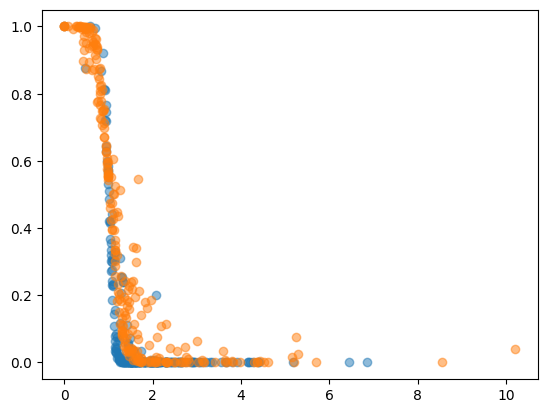

In [82]:
plt.scatter(CNS_wGFP['OddsRatio'].values,CNS_wGFP['pvals'].values,alpha=0.5)
plt.scatter(CNS_no_GFP['OddsRatio'].values,CNS_no_GFP['pvals'].values,alpha=0.5)

# CellPaint data processing

In [12]:
MethodsDict['CellPaint'].keys()

dict_keys(['RawData', 'PlateMap'])

In [13]:
CPdata=MethodsDict['CellPaint']['RawData']
CPPlateMap=MethodsDict['CellPaint']['PlateMap']

In this experiment, replicate wells existed across 3 plates: BR00146927, BR00146928, BR00146929. In all cases, the platemap is the same. Note that at this stage there is 1 preprocessing step that we exclude here, which is simply removing the brightfield features.

In [14]:
CPdata.keys()

dict_keys(['BR00146928', 'BR00146927', 'BR00146929'])

In [15]:
youngwells=['A11','A13','B11','B13','C11','C13','D11','D13','E11','E13','F11','F13','G11','G13','H11','H13','I11','I13','J11','J13','K11','K13','L11','L13','M11','M13','N11','N13','O11','O13','P11','P13']
oldwells=['A12','A14','A23','A24','B01','B03','B05','B12','B14','B16','B18','C01','C09','C12','C14','C24','D12','D14','E12','E14','E18','E24','F03','F12','F14','F18','G12','G14','G24','H12','H14','I12','I14','I18','I24','J12','J14','K01','K12','K14','K24','L01','L03','L09','L12','L14','M12','M14','M24','N02','N05','N12','N14','O12','O14','O19','O22','O23','O24','P12','P14','P15']


Grab all the untreated old (55yo) and young (25yo) cells across all three plates:

In [17]:
oldV1cells=pd.concat([pd.concat([CPdata['BR00146928'][key] for key in oldwells]),pd.concat([CPdata['BR00146927'][key] for key in oldwells]),pd.concat([CPdata['BR00146929'][key] for key in oldwells])])
youngV1cells=pd.concat([pd.concat([CPdata['BR00146928'][key] for key in youngwells]),pd.concat([CPdata['BR00146927'][key] for key in youngwells]),pd.concat([CPdata['BR00146929'][key] for key in youngwells])])
                                                                               

Although in theory the features should be preserved across all samples, it doesn't hurt to be sure:

In [18]:
commoncolumns=list(set(oldV1cells.columns).intersection(set(youngV1cells.columns)))


The reasoning here is as follows: we want to focus our energy on features that are somewhat low-variance WITHIN an age-cohort. Some of these features will be similar between old/young, and therefore have very little discriminatory power. However, some will be DISsimilar, and these are the features that we want to focus on. 

In [19]:
%%time
oldHYB=oldV1cells.loc[:,commoncolumns]
oldHYB=oldHYB.iloc[1:,:]; oldHYB.reset_index(inplace=True,drop=True) #For whatever reason, there is a single cell in the first row that has corrupted data
oldHYBCV=np.abs(oldHYB.std()/(0.000001+oldHYB.mean())) # A bit of jitter to avoid divide-by-zero
lowoldvar=oldHYBCV[oldHYBCV<0.3]

youngHYB=youngV1cells.loc[:,commoncolumns]
youngHYB=youngHYB.iloc[1:,:]; youngHYB.reset_index(inplace=True,drop=True) #For whatever reason, there is a single cell in the first row that has corrupted data
youngHYBCV=np.abs(youngHYB.std()/(0.000001+youngHYB.mean())) # A bit of jitter to avoid divide-by-zero
lowyoungvar=youngHYBCV[youngHYBCV<0.3]

commonlowvar=list(set(lowoldvar.index).intersection(set(lowyoungvar.index)))

CPU times: user 16 s, sys: 5.69 s, total: 21.7 s
Wall time: 21.7 s


In [20]:
hyb=pd.concat([oldHYB.loc[:,commonlowvar].mean(),youngHYB.loc[:,commonlowvar].mean()],axis=1)

This is really the extent of the data treatment. Unlike scRNA, the features here are on different scales and are measured in different units, so we did not opt for a global normalization scheme. It would be reasonable to z-score the features -- in theory I do not believe this should affect the results of the classifier, though I am not 100% certain this extends to certain quantities like the Gini purity/importance of every feature.

# AdaBoost with abstention -- requires previous section (CellPaint data processing) to have been run

Some bookkeeping/cleanup is necessary, as certain features naturally cast NaN values in unpleasant places (for instance, there is a feature that indexes the z-position of the cell, which will always be NaN as our data is extracted from z-cuts of an image):

In [21]:
def ConditionRowdyNANdf(dframe):
    newframe=dframe.iloc[1:,1:].copy()
    newframe.replace([np.inf, -np.inf], np.nan,inplace=True);
    featNAsum=newframe.isna().sum()
    badcols=featNAsum[featNAsum>0.05*len(dframe)].index
    newframe.drop(badcols,inplace=True,axis=1)
    newframe.dropna(axis=0,how='any',inplace=True)
    
    return newframe

As we (briefly) discuss in the Methods/main text, there are a few ways to handle abstention with AdaBoost. At first we hard-coded our own approach. However, we realized that an easier, more publicly-accessible way to handle this was simply to riff off the scikit-learn implementation of Adaboost and handle abstention the back end, which comes in a few cells.

In [22]:
def TrainNBaseClassifiers(N_class, n_estim, oldHYB, youngHYB, commonlowvar):
    # N_class = number of classifiers desired, often 10 in what was used in the manuscript
    # n_estim = number of rounds of boosting, often 300 in the main analysis
    # oldHYB, youngHYB, commonlowvar: the old/young cells and their shared low-variance features from the CellPaint Data Processing section
    
    classifierdict={} #We will store each trained classifier as a key
    olddf=oldHYB.loc[:,commonlowvar]; oldcount=len(olddf)
    youngdf=youngHYB.loc[:,commonlowvar]; youngcount=len(youngdf)
    commonfeat2=commonlowvar
    
    #This next bit is checking which class is the minority. We implement bagging, so every classifier will be trained on a precisely 50/50 class-balanced sample
    if oldcount>youngcount:
        #Old majority young minority
        majclass=olddf.loc[:,commonfeat2]; majclass['Age']='old'
        minclass=youngdf.loc[:,commonfeat2]; minclass['Age']='young'
    else:
        #Young majority old minority
        minclass=olddf.loc[:,commonfeat2]; minclass['Age']='old'
        majclass=youngdf.loc[:,commonfeat2]; majclass['Age']='young'

    mincount=len(minclass)
    
    for modelnum in range(N_class):
        print(modelnum)
        downsamp=resample(majclass,replace=False,n_samples=mincount) #Bagging the samples
        comb=pd.concat([minclass,downsamp]); comb.reset_index(inplace=True,drop=True); 
        comb2=ConditionRowdyNANdf(comb)
        X=comb2.loc[:,comb2.columns != 'Age']
        y=comb2.Age

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3) # 70% training and 30% test
        adaclf = AdaBoostClassifier(n_estimators=n_estim,algorithm='SAMME')
        adaclf.fit(X_train, y_train)

        y_pred=adaclf.predict(X_test)
        print("Test Accuracy:",metrics.accuracy_score(y_test, y_pred))
        feature_imp = pd.Series(adaclf.feature_importances_).sort_values(ascending=False)
        nfeat=np.sum(np.cumsum(np.sort(feature_imp)[::-1])<0.999)
        print("Number of features used: ",nfeat)
        classifierdict[modelnum]=adaclf
    
    
    
    return classifierdict

Running this at a meager 2 voters with 50 rounds of boosting each takes ~15 minutes on the machine specs given in the README. It's a pretty time-consuming process to scale up to what we did in the paper. 

In [27]:
%%time
EXAMP_class_dict=TrainNBaseClassifiers(2,50,oldHYB,youngHYB,commonlowvar)

<ipython-input-22-faf90e407704>:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  majclass=olddf.loc[:,commonfeat2]; majclass['Age']='old'
<ipython-input-22-faf90e407704>:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  minclass=youngdf.loc[:,commonfeat2]; minclass['Age']='young'


0
Test Accuracy: 0.8412711313394018
Number of features used:  29
1
Test Accuracy: 0.8409201755812064
Number of features used:  31
CPU times: user 13min 35s, sys: 13.9 s, total: 13min 49s
Wall time: 13min 49s


This next code snippet is just bookkeeping, to organize the perturbed data into a more amenable structure

In [38]:
def HerdPerturbationsv1(datadict,platemap):
    perturblist=platemap['ORF'].unique(); perturbdict={}
    for key in datadict:
        subdict={}
        for perturb in perturblist:
            mywells=platemap[platemap.ORF==perturb]['Well '].unique()
            myframe=pd.concat([datadict[key][well] for well in mywells],axis=0)
            subdict[perturb]=myframe
        perturbdict[key]=subdict
    
    return perturblist, perturbdict

In [39]:
%%time
perturblistv1,perturbdictv1=HerdPerturbationsv1(CPdata,CPPlateMap)

CPU times: user 18 s, sys: 9.04 s, total: 27 s
Wall time: 27 s


In [45]:
%%time
MasterPertList=[]
for key in perturbdictv1.keys():
    MasterPertList.append(list(perturbdictv1[key].keys()))
MasterPertList=list(set(flatten(MasterPertList)))
print(len(MasterPertList)) # Print the number of perturbations present

# Just a little more massaging of how the perturbation cell data is organized
MasterPert={}
for pert in MasterPertList:
    pertbox=[]
    for key in perturbdictv1:
        try:
            pertbox.append(perturbdictv1[key][pert])
        except:
            noperthere=1
    MasterPert[pert]=pd.concat(pertbox)

280
CPU times: user 17.6 s, sys: 1.46 s, total: 19 s
Wall time: 19 s


The next snippet is how we apply the classifiers we've trained, which includes the abstention step. The actual best abstention rate needs to be dialed in by applying the code to the old cells.

In [46]:
def PredictLibrary(nummodels,modeldict,targset,abst_thresh):
    #nummodels = number of models in the classifier dictionary
    #modeldict = classifier dictionary
    #targset = cells to classify
    #abst_thresh = The abstention threshold. Cells with a per-model class probability Cp such that |Cp-0.5|<abst_thresh will be abstained upon. 

    targpred=0; tind=0;
    for mod in range(0,nummodels):
        #Make predictions
        adaclf=modeldict[mod]; featlist=list(adaclf.feature_names_in_) # Make sure the features we will test are the same as train!
        targset_clean=targset.loc[:,featlist]; targset_clean.replace([np.inf, -np.inf], np.nan,inplace=True); targset_clean.dropna(axis=0,how='any',inplace=True) #Clean up the test data
        ntp=adaclf.predict_proba(targset_clean) #Predict class probabilities
        nti=np.abs(0.5-ntp[:,1])>abst_thresh #Check which cells to abstain upon
        targpred+=ntp*nti[:,None]; tind+=nti; #Keep track of class probabilities for non-abstained cells
    targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain
    targpred=targpred[~np.isnan(targpred).any(axis=1)] #Make sure no NaNs sneak in

    predset=[i[1] for i in targpred] #Degeneracy because i[0] = 1-i[1]
    abfrac=(len(targset)-len(predset))/len(targset) #What fraction of voters/models abstained; this is how we will calibrate the abstention rate
    print('Fraction Abstained: '+str(abfrac))
    YouthScore=np.sum(np.array(predset)>0.5)/len(predset) #YouthScore is the fraction of cells (mis)classified as young
    print('Youth Score: '+str(YouthScore)+', #cells: '+str(len(targpred)))
    return YouthScore,targpred,abfrac

Test on GFP

In [48]:
%%time
ys,tp,af=PredictLibrary(2,EXAMP_class_dict,MasterPert['GFP'],0.0125)


Fraction Abstained: 0.06252273223248708
Youth Score: 0.1187972841901067, #cells: 25775
CPU times: user 4.01 s, sys: 1.78 s, total: 5.79 s
Wall time: 5.79 s


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


The next snippet calculates the margin of the bagged classifier. We will use the margins of the bagged models on the old control cells to dial in the abstention rate to use for all of the cells. NOTE that the toy example here will very likely give a different optimal abstention rate than that which we employ in the paper (because it is not scaled up to 10 voters with 300 rounds of boosting each)

In [49]:
def GetMargin(tp,abmarg):
    #intended for old only, for calibrating the abstention rate. It is applicable to anything except YOUNG, since the meaning of true-positive class probabilities is flipped for young.
    nums=[i[0]-0.5 for i in tp]
    facts=np.abs(nums)>abmarg
    return np.sum(nums*facts)/facts.sum()

In [51]:
%%time
fracbox=[]; margbox=[]
for abmarg in [0.005,0.0075,0.01,0.0125,0.015,0.0175,0.02,0.0225,0.025]:
    ys,tp,af=PredictLibrary(2,EXAMP_class_dict,MasterPert['Old'],abmarg)
    fracbox.append(af); margbox.append(GetMargin(tp,abmarg))

<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.012463001583854716
Youth Score: 0.15772094575961218, #cells: 137794


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.02495467022138132
Youth Score: 0.15371441591756033, #cells: 136051


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


...

<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.1192406097482316
Youth Score: 0.1234305708124822, #cells: 122895


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.14063339855088045
Youth Score: 0.1164706863480944, #cells: 119910
Fraction Abstained: 0.1637032099933349
Youth Score: 0.10920293767299963, #cells: 116691
CPU times: user 3min 1s, sys: 1min 21s, total: 4min 22s
Wall time: 4min 22s


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


When I ran this in preparing the codebase, I did not see a definitive elbow in this next plot, unlike in the full-manuscript case. But that may change upon a reader's rerun, since the toy example is a very small number of classifiers/rounds of boosting, which injects a large degree of randomness.

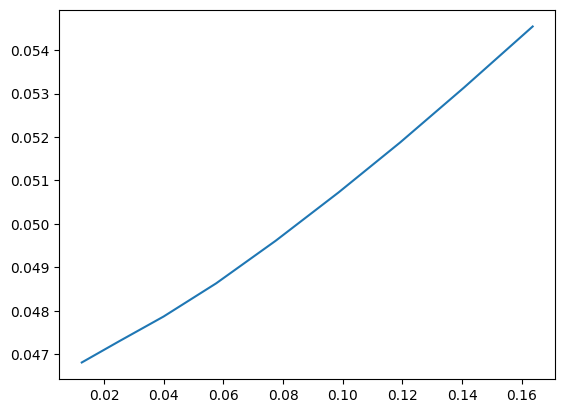

In [56]:
plt.plot(fracbox,margbox)

Running the above steps at the chosen optimal value of the abstention threshold gives the YouthScores for each perturbation.

In [58]:
%%time
ysdict={}; tpdict={}; afdict={}
for perturb in MasterPertList:
    print(perturb)
    ys,tp,af=PredictLibrary(2,EXAMP_class_dict,MasterPert[perturb],0.0125)
    ysdict[perturb]=ys; tpdict[perturb]=tp; afdict[perturb]=af


ACAA2


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.0709197894084856
Youth Score: 0.12366666666666666, #cells: 3000
DDX49


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.05329153605015674
Youth Score: 0.12488174077578051, #cells: 2114
MRPL4


...

<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.10947022972339428
Youth Score: 0.18031060805475124, #cells: 3799
ZDHHC9


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


Fraction Abstained: 0.10665529010238908
Youth Score: 0.1448583253740847, #cells: 3141
DAP
Fraction Abstained: 0.06954732510288066
Youth Score: 0.14329942503317117, #cells: 2261
CPU times: user 2min 11s, sys: 15.9 s, total: 2min 27s
Wall time: 2min 27s


<ipython-input-46-6a0b105fef40>:15: RuntimeWarning: invalid value encountered in divide
  targpred=targpred/tind[:,None] #Average class probabilities per cell over all models which did NOT abstain


# Node2Vec embedding and analysis

In [98]:
MethodsDict['Node2Vec'].keys()

dict_keys(['NetworkA', 'NetworkB', 'NetworkE', 'NetworkF'])

Network A: unweighted edges, well-mapped genes only
Network B: Network A with weighted edges
Network E: same network used for most of analysis
Network F: Network E with weighted edges

Now we need to spin up a Node2Vec instance:

In [99]:
g2v = Node2Vec(
    n_components=64,
    walklen=30
)

Training a model takes about 3 hours and 30 minutes given the machine specs in the README

In [103]:
%%time
adjmat=nx.adjacency_matrix(MethodsDict['Node2Vec']['NetworkA'])
g2v.fit(adjmat)

Making walks... Done, T=2.64
Mapping Walk Names... Done, T=2.01
Training W2V... WARNING: gensim word2vec version is unoptimizedTry version 3.6 if on windows, versions 3.7 and 3.8 have had issues


/opt/conda/lib/python3.9/site-packages/gensim/models/base_any2vec.py:742: UserWarning: C extension not loaded, training will be slow. Install a C compiler and reinstall gensim for fast training.
  warnings.warn(


Done, T=12589.78
CPU times: user 3h 26min 28s, sys: 2h 13min 52s, total: 5h 40min 20s
Wall time: 3h 30min


I'll keep the results from network A in this directory so we can pick up vetting from here

In [104]:
g2v.save('./NetworkA_out')
g2v.save_vectors("./NetworkA_out.bin")

In [6]:
from gensim.models import KeyedVectors
model = KeyedVectors.load_word2vec_format("./NetworkA_out.bin")
model[str(43)]

array([ 1.4481429 ,  0.13376519,  1.6114625 , -0.37592745, -0.92091787,
        0.58431196, -0.09050369, -3.5592155 ,  0.89044946, -2.7702298 ,
       -1.2220411 , -2.5261662 ,  0.5503545 , -0.41662195, -0.61836505,
       -0.08072021, -0.2749423 ,  1.5511999 , -1.0566051 , -0.7266206 ,
       -2.319397  , -1.3774465 ,  0.96875775,  0.78218347,  0.5001586 ,
       -2.8802955 ,  0.90296924, -0.9493098 , -0.7372834 , -0.8871627 ,
       -0.5112074 ,  1.3594259 , -1.1160017 ,  2.279288  ,  1.4126976 ,
        1.9150634 ,  1.4540343 ,  0.097071  , -1.0995411 , -0.0701028 ,
        0.8120774 , -0.975181  , -1.8175867 ,  0.06091148,  0.61075616,
       -1.6483853 , -0.39868203,  1.0887077 ,  1.4246815 ,  0.24678664,
       -1.1269951 , -1.9408516 , -2.064186  ,  1.2905543 , -0.4470941 ,
        0.969676  ,  1.1749917 , -2.4910152 ,  0.45441237, -2.1766856 ,
        0.15616588, -1.764996  ,  0.68976104,  0.27801308], dtype=float32)

 ^^ an example of the learned weights. Let's condense them into a Pandas object that will be easy to use, and save it:

In [24]:
box=[]
GA=MethodsDict['Node2Vec']['NetworkA']
for i in range(len(GA.nodes)):
    entry=list(model[str(i)]); entry.append(list(GA.nodes)[i]); box.append(entry)

df=pd.DataFrame(box)
cbox=['Node2Vec_'+str(i) for i in range(65)]; cbox[-1]='Gene'
df.columns=cbox
df.to_csv(r'./Node2Vec_NetworkA.csv')
df

,Node2Vec_0,Node2Vec_1,Node2Vec_2,Node2Vec_3,Node2Vec_4,Node2Vec_5,Node2Vec_6,Node2Vec_7,Node2Vec_8,Node2Vec_9,...,Node2Vec_55,Node2Vec_56,Node2Vec_57,Node2Vec_58,Node2Vec_59,Node2Vec_60,Node2Vec_61,Node2Vec_62,Node2Vec_63,Gene
0,-0.055982,0.152902,-0.317034,-0.033746,0.100994,-0.040535,-0.371804,0.227521,0.050677,0.294655,...,0.140537,0.268057,0.088784,0.073953,0.093625,0.009977,0.157138,0.093769,-0.319639,A4GALT
1,-0.520193,-0.870501,-2.314480,0.537792,1.929948,1.802846,1.465521,0.841268,1.488874,1.528522,...,-0.944047,-1.806656,1.455609,1.126333,-0.336621,0.384548,1.057895,-0.038466,1.076700,ACOT7
2,0.604939,-0.286762,-1.345761,0.043067,0.895793,0.310634,-2.437469,0.965885,1.563546,0.655851,...,-0.462043,0.088266,2.049660,1.193050,-0.969571,1.885963,1.031200,2.093771,-0.649457,ACSL1
3,1.677319,-0.142675,-0.891075,-1.115870,0.716974,-1.032488,-2.821262,0.403415,-0.081792,0.609632,...,0.043894,1.364136,1.941242,0.917382,0.465276,0.528914,-0.103661,0.637945,1.023582,ADCY3
4,2.412449,-0.116760,-1.283745,0.273883,0.793391,-0.356992,-2.027486,1.774995,1.186164,1.633503,...,-0.596509,0.502325,1.855019,2.303602,-0.567819,0.345625,-0.152048,1.258813,-1.314978,ADH1B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5957,0.087768,-0.076882,0.150720,-0.010535,0.083078,-0.004600,0.084085,0.048715,-0.097235,-0.027460,...,-0.097878,-0.103608,-0.031815,-0.054879,0.017800,0.119773,-0.103164,-0.055757,0.255024,ZNHIT6
5958,0.066455,0.118101,0.353607,-0.209913,0.014172,-0.175801,-0.180030,-0.332740,0.067928,-0.297842,...,-0.002964,0.165524,-0.183396,-0.032456,0.076317,0.056952,-0.084327,0.015708,-0.088741,ZNRD1
5959,0.030413,0.049684,0.293865,-0.177856,-0.071077,-0.192192,0.050419,-0.168720,0.057664,-0.350270,...,0.078849,0.202763,-0.066661,0.030961,-0.153327,0.015587,-0.148670,0.197593,-0.159559,ZPR1
5960,0.029741,-0.010658,-0.501100,-0.271669,0.134012,-0.134704,-0.506074,0.347910,-0.244985,0.213935,...,-0.079926,0.173608,0.307643,0.242007,-0.029534,0.225842,-0.130288,0.332839,-0.115918,ZRANB2


Let's load in additional features we might try to train/test on -- the various Youth Scores (for test), the time series, AgeScores, and tsfresh-extracted features:

In [28]:
ExtraFeatures=MethodsDict['Node2Vec']['ExtraFeatures']
ExtraFeatures.head()

,Gene,RNAYS,YouthScore_Hybrid,variance_larger_than_standard_deviation,has_duplicate_max,has_duplicate_min,has_duplicate,sum_values,abs_energy,mean_abs_change,...,Age42,Age43,Age44,Age45,Age46,Age47,Age48,Age49,Age50,AgeScore
0,ANXA2,0.236025,0.180877,1.0,0.0,0.0,0.0,85991.829428,1.517169e+08,311.863555,...,1827.153333,1918.882353,1834.700000,1812.057143,1849.761905,1842.860000,1702.100,1551.158333,1956.641667,0.008507
1,TP53,0.336058,0.181916,1.0,0.0,0.0,0.0,1664.702973,5.505158e+04,4.171738,...,35.430000,29.574706,31.692778,31.121429,36.040952,33.817333,34.616,32.085000,32.534167,-0.003522
2,MRPS2,0.204873,0.089199,1.0,0.0,0.0,0.0,3302.974055,2.218305e+05,10.955733,...,55.676000,56.378235,56.134444,69.121429,50.638095,53.792000,43.704,58.225833,56.097500,-0.025456
3,MAP3K12,0.229058,0.167423,1.0,0.0,0.0,0.0,2212.350702,1.005070e+05,10.483705,...,36.005333,42.836471,45.722778,35.192857,38.188143,39.138667,48.915,51.741667,40.158333,-0.002090
4,DNPEP,0.199388,0.225871,1.0,0.0,0.0,0.0,2387.390027,1.134170e+05,4.666502,...,40.376667,41.653529,42.194444,44.717143,40.471905,41.950667,41.119,46.416667,41.823333,-0.026179


The next snippet of code should be able to re-generate the data used, for instance, in Fig S9. It runs LassoCV, SVM, AdaBoost, and a vanilla DecisionTree on (un)scaled datasets from any of the four networks, for either a "big" dataset (Node2Vec plus ALL of the ExtraFeatures), or a "small" dataset that includes only Node2Vec and the AgeScores.

In [29]:
@ignore_warnings(category=ConvergenceWarning)

def zmax(a):
    return np.max([a,0])

def ProcessN2V(n2vfile,extra_features,usen2v=1,lassoswitch=1,numbags=6):
    ResultDict={}
    if usen2v:
        n2v=pd.read_csv(n2vfile,index_col=0)
        df_final=extra_features.merge(n2v,left_on='Gene',right_on='Gene')

    else:
        df_final=extra_features
    
    #Define a scaled and nonscaled dataset
    unscaled=df_final.copy()
    unscaled_small=df_final.iloc[:,-65:]
    bigscaler=StandardScaler()
    bigscaler.fit(unscaled.iloc[:,3:].astype('double'))
    scaled=pd.DataFrame(bigscaler.transform(unscaled.iloc[:,3:].astype('double')))
    smallscaler=StandardScaler()
    smallscaler.fit(unscaled_small)
    scaled_small=pd.DataFrame(smallscaler.transform(unscaled_small))
    
    #Calculate Lasso, DecisionTree, AdaBoost, and SVM for these 4 datasets
    #Lasso
    if lassoswitch:
        ResultDict['Lasso']={}
        BareLasso1=linear_model.Lasso(alpha=0.1); BareLasso2=linear_model.Lasso(alpha=0.1); BareLasso3=linear_model.Lasso(alpha=0.1); BareLasso4=linear_model.Lasso(alpha=0.1);
        BareLasso1.fit(unscaled.iloc[:,3:].astype('double'),unscaled.RNAYS.astype('double')); BareLasso2.fit(scaled.astype('double'),unscaled.RNAYS.astype('double'))
        BareLasso3.fit(unscaled_small,unscaled.RNAYS.astype('double')); BareLasso4.fit(scaled_small,unscaled.RNAYS.astype('double')); 
        ResultDict['Lasso']['BareLasso']=[BareLasso1.score(unscaled.iloc[:,3:].astype('double'),unscaled.RNAYS.astype('double')),BareLasso2.score(scaled.astype('double'),unscaled.RNAYS.astype('double')),BareLasso3.score(unscaled_small,unscaled.RNAYS.astype('double')),BareLasso4.score(scaled_small,unscaled.RNAYS.astype('double'))]

        RegLasso1 = LassoCV(cv=5, random_state=0).fit(unscaled.iloc[:,3:].astype('double'),unscaled.RNAYS.astype('double')); RegLasso2=LassoCV(cv=5, random_state=0).fit(scaled.astype('double'),unscaled.RNAYS.astype('double'))
        RegLasso3 = LassoCV(cv=5, random_state=0).fit(unscaled_small,unscaled.RNAYS.astype('double')); RegLasso4 = LassoCV(cv=5, random_state=0).fit(scaled_small,unscaled.RNAYS.astype('double'))
        ResultDict['Lasso']['LassoCV']=[RegLasso1.score(unscaled.iloc[:,3:].astype('double'),unscaled.RNAYS.astype('double')),RegLasso2.score(scaled.astype('double'),unscaled.RNAYS.astype('double')),RegLasso3.score(unscaled_small,unscaled.RNAYS.astype('double')),RegLasso4.score(scaled_small,unscaled.RNAYS.astype('double'))]

    
    #DecisionTree -- keep bag loop running for others
    ResultDict['DecisionTree']={}; ResultDict['AdaBoost']={}; ResultDict['SVM']={}
    for bag in range(0,numbags):
        X_train1, X_test1, y_train1, y_test1 = train_test_split(unscaled.iloc[:,3:].astype('double'), unscaled.RNAYS, test_size=0.3)
        X_train2, X_test2, y_train2, y_test2 = train_test_split(scaled.astype('double'), unscaled.RNAYS, test_size=0.3)
        X_train3, X_test3, y_train3, y_test3 = train_test_split(unscaled_small, unscaled.RNAYS, test_size=0.3)
        X_train4, X_test4, y_train4, y_test4 = train_test_split(scaled_small, unscaled.RNAYS, test_size=0.3)

        DetTree1=DecisionTreeRegressor(random_state=0); DetTree1.fit(X_train1,y_train1)
        DetTree2=DecisionTreeRegressor(random_state=0); DetTree2.fit(X_train2,y_train2)
        DetTree3=DecisionTreeRegressor(random_state=0); DetTree3.fit(X_train3,y_train3)
        DetTree4=DecisionTreeRegressor(random_state=0); DetTree4.fit(X_train4,y_train4)

        ResultDict['DecisionTree'][bag]=[zmax(DetTree1.score(X_test1,y_test1)),zmax(DetTree2.score(X_test2,y_test2)),zmax(DetTree3.score(X_test3,y_test3)),zmax(DetTree4.score(X_test4,y_test4))]

    #AdaBoost
        
        Ada1=AdaBoostRegressor(random_state=0, n_estimators=500); Ada1.fit(X_train1,y_train1)
        Ada2=AdaBoostRegressor(random_state=0, n_estimators=500); Ada2.fit(X_train2,y_train2)
        Ada3=AdaBoostRegressor(random_state=0, n_estimators=500); Ada3.fit(X_train3,y_train3)
        Ada4=AdaBoostRegressor(random_state=0, n_estimators=500); Ada4.fit(X_train4,y_train4)
        ResultDict['AdaBoost'][bag]=[zmax(Ada1.score(X_test1,y_test1)),zmax(Ada2.score(X_test2,y_test2)),zmax(Ada3.score(X_test3,y_test3)),zmax(Ada4.score(X_test4,y_test4))]
    
    #SVM
    
        SVM1 = svm.SVR(); SVM1.fit(X_train1,y_train1)
        SVM2 = svm.SVR(); SVM2.fit(X_train2,y_train2)
        SVM3 = svm.SVR(); SVM3.fit(X_train3,y_train3)
        SVM4 = svm.SVR(); SVM4.fit(X_train4,y_train4)
        ResultDict['SVM'][bag]=[zmax(SVM1.score(X_test1,y_test1)),zmax(SVM2.score(X_test2,y_test2)),zmax(SVM3.score(X_test3,y_test3)),zmax(SVM4.score(X_test4,y_test4))]
    
    
    return ResultDict#,X_train1,X_test1,y_train1,y_test1,DetTree1

In [31]:
%%time
out=ProcessN2V('./Node2Vec_NetworkA.csv',ExtraFeatures,1,1,3)
out

/opt/conda/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.379e-01, tolerance: 7.448e-05
  model = cd_fast.enet_coordinate_descent(
/opt/conda/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.849e-05, tolerance: 6.048e-05
  model = cd_fast.enet_coordinate_descent(
/opt/conda/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.696e-05, tolerance: 6.048e-05

CPU times: user 3min 39s, sys: 4min 28s, total: 8min 8s
Wall time: 1min 7s


{'Lasso': {'BareLasso': [0.174517192970859, 0.0, 0.0, 0.0],
  'LassoCV': [0.0, 0.0, 0.025959886873552218, 0.050650283875895874]},
 'DecisionTree': {0: [0.0, 0.0, 0.0, 0.0],
  1: [0.0, 0.0, 0.0, 0.0],
  2: [0.0, 0.0, 0.0, 0.0]},
 'AdaBoost': {0: [0.0, 0.0, 0.0402926887661611, 0.0],
  1: [0.0, 0.0, 0.0, 0.0],
  2: [0.0, 0.0, 0.0, 0.0]},
 'SVM': {0: [0.0, 0.0, 0.0, 0.0],
  1: [0.0, 0.0, 0.0, 0.022050170113244616],
  2: [0.0, 0.0, 0.0, 0.0]}}